In [ ]:
import pandas as pd 

data1 = pd.read_feather(rf'/project/model_share/share_1_new/factor_csy/fac20250212_fill_zero_sample/2023q1_num-1406.fea')



,Code,date,fac0002,fac0003,fac0004,fac0005,fac0006,fac0007,fac0008,fac0009,...,fac0276,fac0306,fac0308,fac0312,fac0313,fac0314,fac0315,fac0316,fac0317,fac0318
0,000001,20190110,0.682860,-0.204902,-0.444787,0.497025,0.540066,0.426365,-0.467887,0.494823,...,0.031531,0.812572,-0.858767,0.011323,0.244427,0.612764,0.035093,-0.192472,0.464892,-0.480938
1,000002,20190110,0.752874,-0.591779,-0.770947,-0.104821,0.598953,0.455502,-0.777588,-0.109190,...,0.818533,0.648609,-0.594927,0.129850,-0.667739,-0.636850,0.316514,-0.179674,-0.200087,0.715932
2,000004,20190110,1.062199,0.353145,-1.108695,-0.020743,-0.424586,-0.258572,-1.104331,-0.011589,...,1.329640,-0.198776,-0.629472,-0.098940,-0.220989,-0.200117,-3.840570,-0.057508,-0.559469,-3.448990
3,000005,20190110,0.876809,-0.196417,-0.685394,-0.071312,-0.227836,0.038480,-0.630108,-0.059889,...,-0.161453,0.534264,-0.689480,0.202640,1.657809,0.851198,0.332197,1.384689,0.645649,0.567331
4,000006,20190110,1.056498,0.331207,-1.358534,-0.120777,-0.769271,-0.284819,-1.368951,-0.089595,...,0.341791,0.913302,0.074565,-0.050505,-0.049024,0.101671,-0.119647,0.359893,0.279717,-1.073848
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4281845,301622,20241231,0.212024,-0.485517,-1.380898,-0.538076,-0.232054,-0.234227,-1.328368,-0.524021,...,0.109046,1.282760,-1.053939,0.229770,0.232954,0.308976,0.047581,0.622450,0.805508,0.087697
4281846,301626,20241231,0.542301,0.412688,-1.154535,0.212562,-0.520045,-0.499548,-1.210741,0.183214,...,0.204113,0.975999,0.112811,1.282553,1.933830,0.354996,1.269299,2.042849,0.320853,1.215742
4281847,301628,20241231,0.563302,0.497373,-0.690165,0.474910,0.166032,-0.025721,-0.625878,0.434552,...,0.527621,0.729038,0.262637,-0.584064,-0.194084,0.430501,0.036194,-0.252788,0.260425,-0.721096
4281848,301631,20241231,0.485890,0.421591,-0.333466,0.386403,0.398142,0.158226,-0.187083,0.503668,...,1.478402,1.013796,-0.819925,-0.151141,0.982535,0.901476,-0.203738,1.077553,1.049994,-0.193738


In [3]:
Code_list = data1['Code'].unique().tolist()
len(Code_list)

2953

In [ ]:
import numpy as np
import warnings
from numpy.linalg import eigh
import os
import pandas as pd
warnings.filterwarnings("ignore")


'''原始因子部分'''
fac_path = rf'/project/model_share/user96_factor/fac20250212'
fac_name = rf'fill_zero'
fac_data = pd.read_feather(rf'{fac_path}/{fac_name}.fea')



In [8]:
fac_data = fac_data.reset_index().set_index(['date', 'Code'])
fac_data

fac0001   fac0002   fac0003   fac0004   fac0005   fac0006  \
date     Code                                                                 
20190110 000001  0.119363  0.821237 -0.059536 -1.153504  0.581425  0.724608   
         000002  0.085758  0.851033 -0.093417 -1.615491  0.307702  0.872698   
         000004  0.000000  0.982670 -0.010664 -2.093893  0.345942 -1.701296   
         000005  0.025461  0.903775 -0.058793 -1.494310  0.322943 -1.206509   
         000006  0.007533  0.980244 -0.012586 -2.447776  0.300446 -2.568110   
...                   ...       ...       ...       ...       ...       ...   
20241231 301631  0.050926  0.915039 -0.034061 -1.917357  0.481773 -0.272516   
         301622  0.133779  0.841466 -0.115176 -3.804228  0.209021 -2.565662   
         301617  0.062910  0.843350 -0.104364 -1.253927  0.265315  0.817956   
         301585  0.182186  0.701895 -0.203591 -1.773046  0.211406 -0.989083   
         301598  0.187940  0.601071 -0.180383 -2.959208  0.364627 -3.608293   

                  fac0007   fac0008   fac0009   fac0010  ...   fac2781  \
date     Code                                            ...             
20190110 000001  1.078512 -1.151810  0.632271  0.623103  ...  0.000000   
         000002  1.106667 -1.591098  0.332844  0.329859  ...  0.000000   
         000004  0.416667 -2.054558  0.381228  0.384605  ...  0.000000   
         000005  0.703704 -1.381909  0.357284  0.352088  ...  0.000000   
         000006  0.391304 -2.429901  0.342557  0.342557  ...  0.000000   
...                   ...       ...       ...       ...  ...       ...   
20241231 301631  0.949153 -1.568042  0.583732  0.584568  ...  0.000000   
         301622  0.638554 -3.632923  0.238276  0.240920  ...  0.021213   
         301617  1.152542 -1.090992  0.305639  0.306951  ...  0.000000   
         301585  0.895604 -1.406992  0.249861  0.255335  ...  0.000000   
         301598  0.653266 -2.821395  0.417951  0.425868  ... -0.028284   

                   fac2782    fac2783    fac2784    fac2785   fac2786  \
date     Code                                                           
20190110 000001  -0.044463  -0.029907  -0.029907  -0.029907 -0.033665   
         000002  -0.361347  -0.106854  -0.104576  -0.104576 -0.053541   
         000004  -0.049497   0.000000   0.000000   0.000000  0.000000   
         000005  -0.014142   0.000000   0.000000   0.000000  0.000000   
         000006  -0.030237  -0.029665  -0.029861  -0.021213  0.000000   
...                    ...        ...        ...        ...       ...   
20241231 301631 -46.847928 -46.181955  -0.767221  -0.220519 -0.236220   
         301622  44.853988  41.496090  41.260431  23.036210  0.139636   
         301617  -1.050681  -1.008375  -0.067890  -0.060341 -0.061074   
         301585  -3.429325  -3.517944  -3.857659  -0.183988 -0.067287   
         301598  -0.565438  -0.141277  -0.141277  -0.111932 -0.107839   

                  fac2787   fac2788   fac2789   fac2790  
date     Code                                            
20190110 000001 -0.015736 -0.010000  0.000000  0.000000  
         000002 -0.012910 -0.007071  0.000000  0.000000  
         000004  0.000000  0.000000  0.000000  0.000000  
         000005  0.000000  0.000000  0.000000  0.000000  
         000006  0.000000  0.000000  0.000000  0.000000  
...                   ...       ...       ...       ...  
20241231 301631 -0.236220 -0.236220 -0.060828 -0.053774  
         301622  0.139636  0.107695  0.021679  0.022174  
         301617 -0.061074 -0.055227 -0.050000 -0.050000  
         301585 -0.045423 -0.039051 -0.020000 -0.020000  
         301598 -0.073536 -0.054626 -0.070711 -0.050000  

[4281850 rows x 2790 columns]

In [5]:
import numpy as np
sel_fac = np.loadtxt(rf"/home/user96/20250908_Attention/model_test/nn--fac20250212_fill_zero--label1--dropout0.2/ALL2023q1-feature_map.fea", dtype=str)
sel_fac = list(sel_fac)
sel_fac = [x.split("=")[0] for x in sel_fac]
sel_fac

['fac0002',
 'fac0003',
 'fac0004',
 'fac0005',
 'fac0006',
 'fac0007',
 'fac0008',
 'fac0009',
 'fac0010',
 'fac0011',
 'fac0012',
 'fac0013',
 'fac0020',
 'fac0027',
 'fac0028',
 'fac0029',
 'fac0037',
 'fac0051',
 'fac0066',
 'fac0079',
 'fac0082',
 'fac0099',
 'fac0104',
 'fac0107',
 'fac0114',
 'fac0117',
 'fac0132',
 'fac0144',
 'fac0145',
 'fac0147',
 'fac0154',
 'fac0177',
 'fac0204',
 'fac0206',
 'fac0209',
 'fac0236',
 'fac0246',
 'fac0265',
 'fac0273',
 'fac0274',
 'fac0276',
 'fac0306',
 'fac0308',
 'fac0312',
 'fac0313',
 'fac0314',
 'fac0315',
 'fac0316',
 'fac0317',
 'fac0318',
 'fac0319',
 'fac0320',
 'fac0408',
 'fac0469',
 'fac0476',
 'fac0477',
 'fac0478',
 'fac0481',
 'fac0482',
 'fac0483',
 'fac0484',
 'fac0485',
 'fac0489',
 'fac0490',
 'fac0491',
 'fac0494',
 'fac0495',
 'fac0496',
 'fac0497',
 'fac0498',
 'fac0500',
 'fac0502',
 'fac0503',
 'fac0504',
 'fac0556',
 'fac0558',
 'fac0560',
 'fac0568',
 'fac0576',
 'fac0578',
 'fac0582',
 'fac0583',
 'fac0601',
 'fa

In [ ]:
de

0.0006080301160496685

In [20]:
normalized_eigenvalues

array([ 9.99434957e-01,  5.59014708e-04,  6.02840830e-06, ...,
       -3.11207528e-16, -3.29426563e-16, -3.35865472e-16])

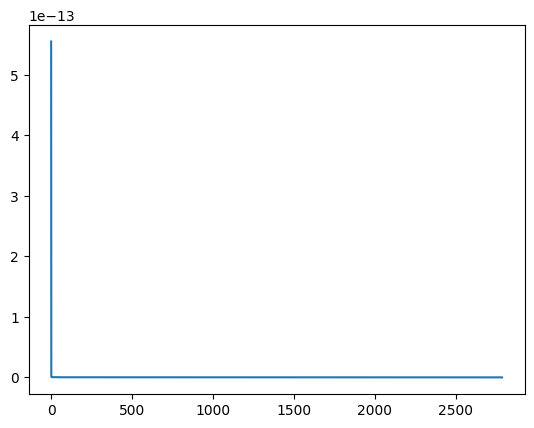

In [26]:
import matplotlib.pyplot as plt
plt.plot(normalized_eigenvalues[4:])
plt.show()